In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report, roc_auc_score ,roc_curve
from sklearn.preprocessing import label_binarize,LabelEncoder
from sklearn.preprocessing import StandardScaler

In [ ]:
#Load the dataset
df=pd.read_csv('/content/BankNoteAuthentication.csv')
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
df.shape

(1372, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
df.describe()

,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [ ]:
df.isnull().sum()

,0
variance,0
skewness,0
curtosis,0
entropy,0
class,0


In [ ]:
#Checking if there are any duplicates
print("No.of records:",df.duplicated().sum())

No.of records: 24


In [ ]:
#remove duplicate records
df.drop_duplicates(inplace=True)
df.shape

(1348, 5)

In [ ]:
#idetify null values
df.isnull().sum()

,0
variance,0
skewness,0
curtosis,0
entropy,0
class,0


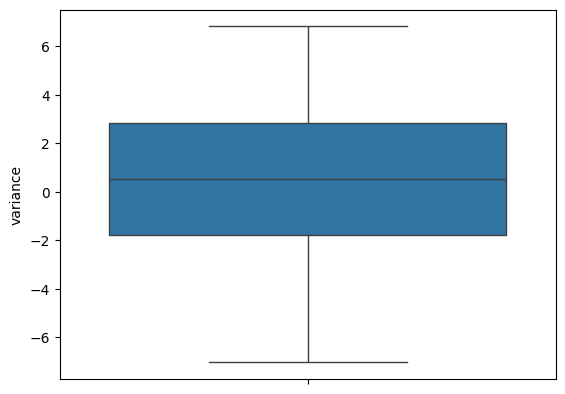

In [ ]:
#identify outliers
sns.boxplot(df['variance'])
plt.show()


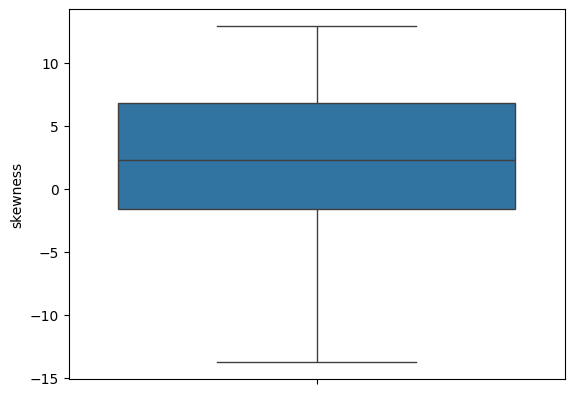

In [ ]:
#identify outliers in skewness
sns.boxplot(df['skewness'])
plt.show()

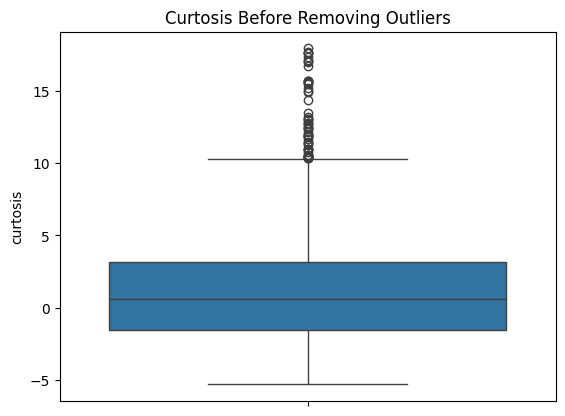

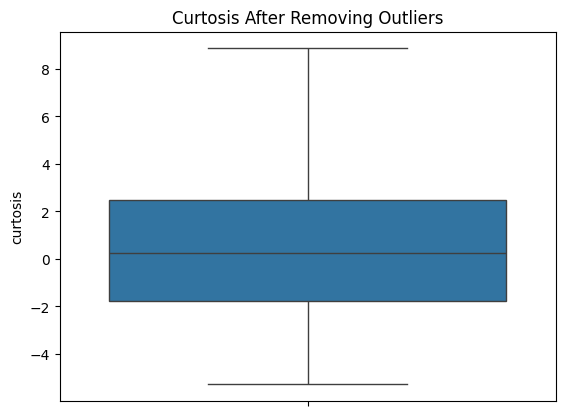

In [ ]:
# identify outliers in curtosis
sns.boxplot(df['curtosis'])
plt.title("Curtosis Before Removing Outliers")
plt.show()

# remove outliers in curtosis
while True:
    Q1 = df['curtosis'].quantile(0.25)
    Q3 = df['curtosis'].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    old_shape = df.shape

    df = df[
        (df['curtosis'] >= lower_limit) &
        (df['curtosis'] <= upper_limit)
    ]

    if df.shape == old_shape:
        break

# check outliers after removal
sns.boxplot(df['curtosis'])
plt.title("Curtosis After Removing Outliers")
plt.show()

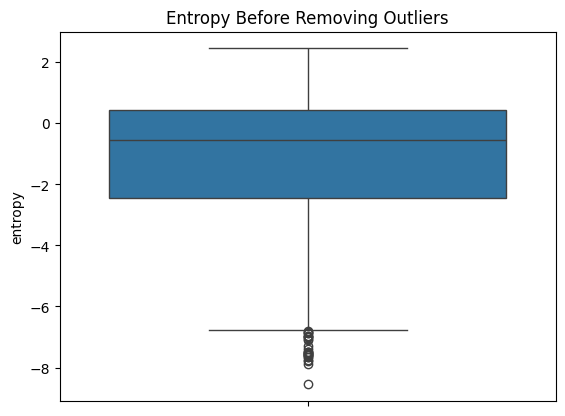

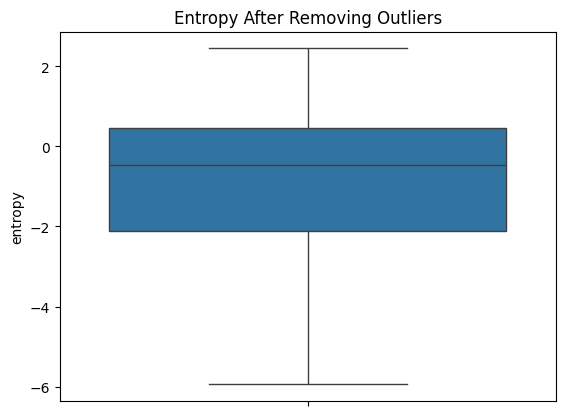

In [ ]:
# identify outliers in entropy
sns.boxplot(df['entropy'])
plt.title("Entropy Before Removing Outliers")
plt.show()

# remove outliers in entropy
while True:
    Q1 = df['entropy'].quantile(0.25)
    Q3 = df['entropy'].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    old_shape = df.shape

    df = df[
        (df['entropy'] >= lower_limit) &
        (df['entropy'] <= upper_limit)
    ]

    if df.shape == old_shape:
        break

# check outliers after removal
sns.boxplot(df['entropy'])
plt.title("Entropy After Removing Outliers")
plt.show()

In [ ]:
#label encoding for target
le=LabelEncoder()
df['class']=le.fit_transform(df['class'])
df.head()

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
x=df.iloc[:,:-1]
y=df.iloc[:,-1]

In [ ]:
#split the data into training and testing
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=15,stratify=y)

In [ ]:
#standardization
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [ ]:
#model building
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [ ]:
#predictions on test data
y_pred=knn.predict(x_test)

In [ ]:
#evaluation metrics
accuracy_score(y_test,y_pred)
classification_report(y_test,y_pred)
confusion_matrix(y_test,y_pred)

array([[142,   2],
       [  0,  98]])

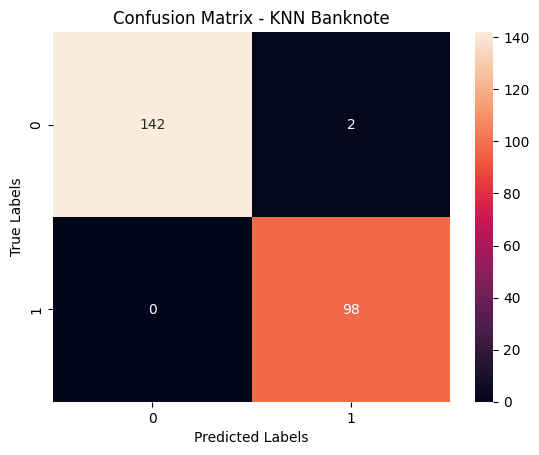

In [ ]:
#confusion matrix
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True,fmt='d')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - KNN Banknote')
plt.show()

In [ ]:
y_pred = knn.predict(x_test)
y_proba = knn.predict_proba(x_test)[:,1]
print("Accuracy:", accuracy_score(y_test, y_pred))
roc_auc = roc_auc_score(y_test,y_proba)
print("ROC-AUC Score:", roc_auc)

Accuracy: 0.9917355371900827
ROC-AUC Score: 0.9965277777777778


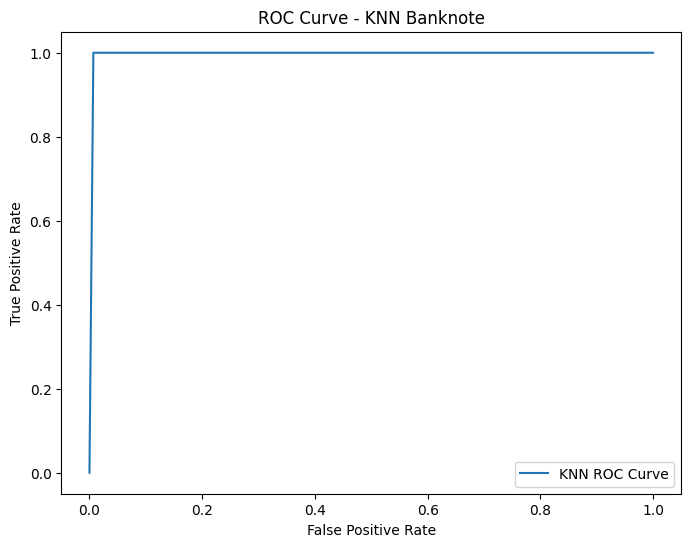

In [ ]:
#roc curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr,tpr,label='KNN ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN Banknote')
plt.legend()
plt.show()

In [ ]:
overall_auc = roc_auc_score(y_test,y_proba)
print("Overall ROC-AUC:", overall_auc)

Overall ROC-AUC: 0.9965277777777778
